# Cvičení 07: Ordinační analýza II — Kernel PCA




In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Nejdříve se podíváme na data
Ordinační analýza popisuje vztahy mezi objekty pomocí několika souřadnic.
PCA hledá souřadnice s velkým rozptylem; sama neví, do jaké třídy bod patří.
Vygenerujeme 100 bodů tvořících dva půlměsíce.

**Doplňte:** do bodového grafu první a druhý sloupec matice `X`.
`y` obsahuje třídy a použijeme jej pouze pro barvu bodů.


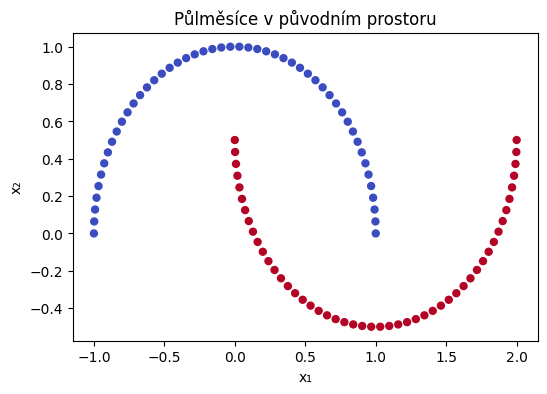

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=100, random_state=123)

plt.figure(figsize=(6, 4))
plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm', s=25)
plt.xlabel('x₁')
plt.ylabel('x₂')
plt.title('Půlměsíce v původním prostoru')
plt.show()


**Společná diskuse**

1. Dokážeme třídy oddělit jedinou přímkou?
  - Ne, data jsou lineárně neseparabilní (tvar půlměsíců se vzájemně prolíná).
2. Pomůže pouhé otočení obrázku?
  - Ne, otočení je lineární transformace, takže zakřivení a vzájemné propletení tříd nijak nezmění.
3. Jaký nelineární klasifikátor nebo transformaci znáte?
  - Z klasifikátorů např. SVM s RBF jádrem, rozhodovací stromy či neuronové sítě; z transformací polynomické rozšíření příznaků nebo Kernel PCA.


## 2. Lineární PCA: centrování a kovariance
Řádky $X$ jsou objekty, sloupce příznaky. Odečteme průměr každého sloupce:
$$X_c=X-\bar X.$$
Poté spočítáme výběrovou kovarianční matici:
$$C=\frac{X_c^T X_c}{n-1}.$$

**Doplňte:** sloupcové průměry (`axis=0`), centrovaná data a kovarianční matici.


In [ ]:
X_mean = np.mean(X, axis=0)
X_centered = X - X_mean
X_cov = np.dot(X_centered.T, X_centered) / (len(X) - 1)

print('Průměry po centrování:', X_centered.mean(axis=0))
print('Kovarianční matice:')
print(X_cov)


Průměry po centrování: [-2.10942375e-17  9.21485110e-17]
Kovarianční matice:
[[ 0.76767677 -0.18872406]
 [-0.18872406  0.24309412]]


**Společná diskuse**

1. Jaký rozměr má `X_cov` a co je na diagonále?
  - Má rozměr $2 \times 2$ (počet příznaků $\times$ počet příznaků) a na diagonále jsou rozptyly (variance) jednotlivých příznaků $x_1$ a $x_2$.
2. Proč vychází průměr například `1e-16` místo přesné nuly?
  - Je to důsledek zaokrouhlovacích chyb při reprezentaci reálných čísel s plovoucí řádovou čárkou v počítači (tzv. floating-point arithmetic).
3. Je centrování totéž jako standardizace?
  - Není – centrování pouze posune data odečtením průměru ($\mu = 0$), zatímco standardizace je navíc ještě vydělí směrodatnou odchylkou ($\sigma = 1$).
  - standardizace se nedělá, jestliže chceme udržet geometrické tvary v prostoru, protože bychom si zkreslili vzdálenosti


## 3. Lineární PCA: hlavní směry
Vlastní vektory kovarianční matice určují hlavní směry, vlastní čísla rozptyly v těchto směrech.
Pro symetrickou matici použijeme `np.linalg.eigh`. Jeho výstup seřadíme sestupně.

**Doplňte:** vlastní rozklad kovarianční matice a podíl každého vlastního čísla na jejich součtu.


In [ ]:
pca_values, pca_vectors = np.linalg.eigh(X_cov)
order = np.argsort(pca_values)[::-1]
pca_values = pca_values[order]
pca_vectors = pca_vectors[:, order]

variance_ratio = pca_values / np.sum(pca_values)
print('Vlastní čísla:', pca_values)
print('Podíly vysvětleného rozptylu:', variance_ratio)


Vlastní čísla: [0.82851624 0.18225465]
Podíly vysvětleného rozptylu: [0.81968748 0.18031252]


**Společná diskuse**

1. Proč seřazujeme současně vlastní čísla i sloupce vlastních vektorů?
  - Každé vlastní číslo přímo odpovídá konkrétnímu sloupci vlastního vektoru, takže seřazením zachováváme jejich správné spárování.
2. Co znamená první podíl rozptylu?
  - Znamená, že první hlavní komponenta zachycuje téměř 82 % veškeré variability (rozptylu) v datech.
3. Zaručuje největší rozptyl nejlepší oddělení tříd?
  - Nezaručuje, protože PCA je nepodmíněná (unsupervised) metoda a směr s největším rozptylem může obě třídy slít do sebe.

## 4. Lineární PCA: nové souřadnice a jejich graf
Souřadnice v hlavních směrech dostaneme projekcí **centrovaných** dat:
$$Z=X_cV.$$
**Doplňte:** maticový součin pro projekci. Vykreslovací kód je hotový.
První dva grafy ukazují každou komponentu samostatně, třetí obě dohromady.


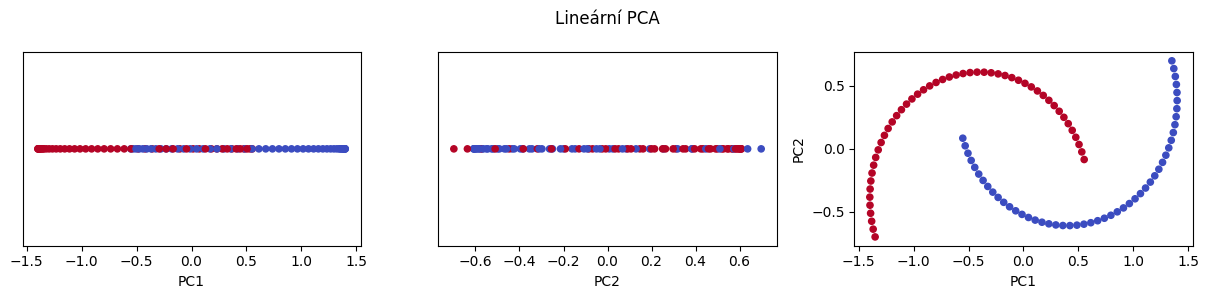

In [ ]:
Z_pca = np.dot(X_centered, pca_vectors)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].scatter(Z_pca[:, 0], np.zeros(len(X)), c=y, cmap='coolwarm', s=20)
axes[0].set(xlabel='PC1', yticks=[])
axes[1].scatter(Z_pca[:, 1], np.zeros(len(X)), c=y, cmap='coolwarm', s=20)
axes[1].set(xlabel='PC2', yticks=[])
axes[2].scatter(Z_pca[:, 0], Z_pca[:, 1], c=y, cmap='coolwarm', s=20)
axes[2].set(xlabel='PC1', ylabel='PC2')
fig.suptitle('Lineární PCA')
plt.tight_layout()
plt.show()


**Společná diskuse**

1. Získali jsme lineárně oddělitelné třídy?
  - Nezískali, třídy zůstávají vzájemně zakřivené a promíchané, protože lineární PCA data pouze otočila a posunula.
2. Ztratili jsme při ponechání obou komponent nějakou informaci?
  - Neztratili, protože jsme zachovali obě dvě dimenze z původních dvou (došlo jen k bezeztrátové rotaci souřadného systému).
3. Co znamenají nuly ve druhé souřadnici prvních dvou grafů?
  - Slouží čistě pro vizualizaci jednorozměrného rozptylu podél osy $x$, aby se body vykreslily na jedné vodorovné přímce ($y = 0$).


## 5. Kernel trick na konkrétních číslech
Zkusme transformaci $\phi(x_1,x_2)=(x_1,x_2,x_1^2+x_2^2)$.
Pro body $A=(1,2)$ a $B=(3,4)$ lze spočítat skalární součin dvěma způsoby:
$$\phi(A)^T\phi(B)=A^TB+(A^TA)(B^TB).$$
Pravá strana používá jen původní souřadnice: je to příslušný kernel $k(A,B)$.

**Doplňte:** explicitní skalární součin transformovaných bodů a poté přímý kernelový výraz.
Operátor `@` pro dva jednorozměrné vektory počítá skalární součin.


In [ ]:
A = np.array([1., 2.])
B = np.array([3., 4.])
phi_A = np.array([A[0], A[1], A[0]**2 + A[1]**2])
phi_B = np.array([B[0], B[1], B[0]**2 + B[1]**2])

explicit = phi_A @ phi_B
implicit = A @ B + (A @ A) * (B @ B)
print('Transformované body:', phi_A, phi_B)
print('Explicitně:', explicit, '| pomocí kernelu:', implicit)


Transformované body: [1. 2. 5.] [ 3.  4. 25.]
Explicitně: 136.0 | pomocí kernelu: 136.0


**Společná diskuse**

1. Jaký výsledek dostaneme? Zkuste jej ověřit ručně.
  - Výsledek je 136, protože:
    - $A^T B = 1\cdot 3 + 2\cdot 4 = 11$$A^T
    - A = 1^2 + 2^2 = 5$$B^T
    - B = 3^2 + 4^2 = 25$$11 + (5 \cdot 25) = 11 + 125 = 136$.
2. „Stejně jsme to museli spočítat.“ Co tedy kernel trick vlastně šetří?
  - Šetří obrovské výpočetní nároky i paměť, protože umožňuje pracovat v libovolně vysoké (či nekonečnědimenzionální) dimenzi, aniž bychom do ní museli body explicitně transformovat a ukládat.

## 6. Polynomiální kernel: matice skalárních součinů
Nyní použijeme standardní polynomiální kernel
$$k(a,b)=(a^Tb+1)^p.$$
Matice $K$ obsahuje tyto skalární součiny mezi všemi dvojicemi trénovacích bodů.
Začneme stupněm 10.

**Doplňte:** matici `(X @ X.T + 1)` umocněnou po prvcích na `degree`.


In [ ]:
degree = 10
K_poly = (X @ X.T + 1) ** degree
print('Rozměr kernelové matice:', K_poly.shape)
print('První tři řádky a sloupce:')
print(K_poly[:3, :3])


Rozměr kernelové matice: (100, 100)
První tři řádky a sloupce:
[[1.02400000e+03 2.85818900e+01 1.54982013e+03]
 [2.85818900e+01 2.29630701e+02 2.95674360e+03]
 [1.54982013e+03 2.95674360e+03 1.47893283e+05]]


**Společná diskuse**

1. Proč má matice 100 × 100, když původní data mají jen dva příznaky?
  - Protože jde o Gramovu matici (kernelovou matici), která obsahuje vzájemné skalární součiny mezi všemi dvojicemi z celkových 100 pozorování ($N \times N$).
2. Co znamená prvek `K_poly[i, j]`?
  - Představuje míru podobnosti (skalární součin po nelineárním zobrazení $\phi(x_i)^T \phi(x_j)$) mezi $i$-tým a $j$-tým datovým bodem.
3. Proč může být stupeň 10 citlivý na velké hodnoty vstupních souřadnic?
  - Při umocňování na 10. stupeň i malé zvětšení souřadnic způsobí exponenciální nárůst čísel (riziko numerického přetečení a dominance odlehlých hodnot).


## 7. Centrovaní v novém prostoru
Pro PCA potřebujeme odečíst průměr v příznakovém prostoru. Pouhé centrování původního $X$
to u nelineární transformace obecně nezajistí.

S maticí $J$, jejíž všechny prvky jsou $1/n$, platí
$$K_c=K-JK-KJ+JKJ.$$
**Doplňte:** centrovanou kernelovou matici podle vzorce. `@` označuje násobení matic.


In [ ]:
n = len(X)
J = np.ones((n, n)) / n
K_poly_c = K_poly - J @ K_poly - K_poly @ J + J @ K_poly @ J

print('Průměry prvních pěti sloupců po centrování:')
print(K_poly_c.mean(axis=0)[:5])


Průměry prvních pěti sloupců po centrování:
[2.34285835e-11 3.43425199e-11 3.28873284e-11 2.27009878e-11
 1.84809323e-11]


**Společná diskuse**

1. Jaké by měly být řádkové a sloupcové průměry po centrování?
  - Měly by být teoreticky přesně nulové ($0$).
2. Proč nestačí odečíst průměr původních souřadnic?
  - Protože nelineární transformace $\phi(x)$ nezachovává průměry – i když jsou původní data centrovaná, jejich transformované obrazy $\phi(x)$ v novém prostoru nulový průměr mít nebudou.
3. Jak poznat, zda je malý nenulový průměr jen zaokrouhlovací chyba?
  - Pozná se to podle řádu hodnoty – výsledky řádově $10^{-11}$ až $10^{-16}$ jsou v porovnání s původními hodnotami matice zanedbatelné a odpovídají strojové přesnosti (floating-point precision).


## 8. Z kernelové matice k hlavním komponentám
V Kernel PCA místo kovarianční matice rozkládáme centrovanou kernelovou matici. Ta zachycuje podobnosti (analogicky k tomu jak to dělala kovarianční matice) mezi body v novém, často mnohorozměrném prostoru. Díky tomu dokážeme vypočítat hlavní komponenty, aniž bychom museli explicitně vytvářet souřadnice bodů v tomto prostoru.
Nejdříve najdeme vlastní čísla a vektory. Ponecháme dvě největší kladná vlastní čísla.
**Doplňte:** vlastní rozklad `K_poly_c`.


In [ ]:
poly_values, poly_vectors = np.linalg.eigh(K_poly_c)
order = np.argsort(poly_values)[::-1]
poly_values = poly_values[order][:2]
poly_vectors = poly_vectors[:, order][:, :2]
print('Dvě největší vlastní čísla:', poly_values)


Dvě největší vlastní čísla: [72985861.43481576  5695220.23236916]


**Společná diskuse**

1. V jakém prostoru leží hlavní směry klasické PCA a Kernel PCA?
  - U klasické PCA leží v původním vstupním prostoru příznaků ($\mathbb{R}^2$), zatímco u Kernel PCA leží v novém, transformovaném mnohorozměrném prostoru příznaků $\phi(X)$ (přesněji v podprostoru tvořeném obrazy datových bodů).
2. Jaký rozměr mají nyní vybrané vlastní vektory?
  - Mají délku 100 (obecně $N$, rozměr $100 \times 1$ pro každý vektor, celá matice poly_vectors má rozměr $100 \times 2$), protože rozkládáme matici podobností $N \times N$, kde každý prvek vektoru odpovídá váze jednoho trénovacího bodu.

### 8b. Normalizace a projekce
Vlastní vektory (u) vydělíme odmocninou vlastního čísla, aby měly jednotkovou délku, označíme `poly_alphas`:
$$\alpha_j=u_j/\sqrt{\lambda_j},\qquad $$

U lineární PCA toto neděláme, protože tam mají vlastní vektory délku 1 automaticky.

**Doplňte:** dělení vektorů odmocninou vlastních čísel a následnou projekci.
NumPy při dělení automaticky přiřadí každému sloupci jeho vlastní číslo.


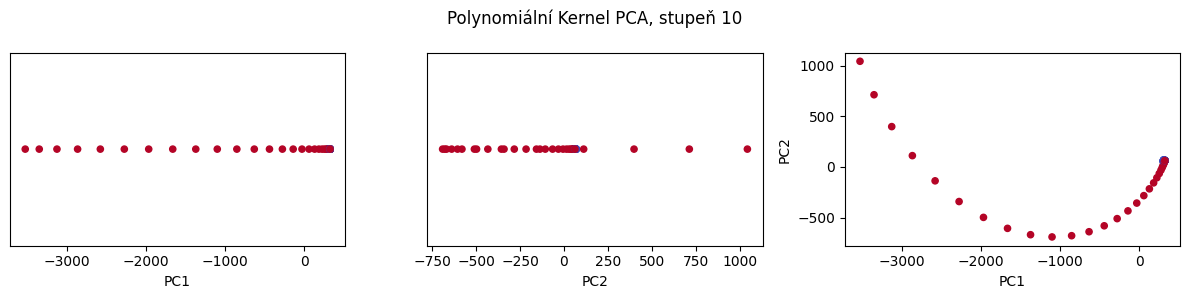

In [ ]:
# Normalizace: každý vlastní vektor vydělíme odmocninou příslušného vlastního čísla
poly_alphas = poly_vectors / np.sqrt(poly_values)

# Projekce centrované kernelové matice: Z = K_c @ alphas
Z_poly = K_poly_c @ poly_alphas

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].scatter(Z_poly[:, 0], np.zeros(len(X)), c=y, cmap='coolwarm', s=20)
axes[0].set(xlabel='PC1', yticks=[])
axes[1].scatter(Z_poly[:, 1], np.zeros(len(X)), c=y, cmap='coolwarm', s=20)
axes[1].set(xlabel='PC2', yticks=[])
axes[2].scatter(Z_poly[:, 0], Z_poly[:, 1], c=y, cmap='coolwarm', s=20)
axes[2].set(xlabel='PC1', ylabel='PC2')
fig.suptitle('Polynomiální Kernel PCA, stupeň 10')
plt.tight_layout()
plt.show()


**Společná diskuse**

1. Zlepšilo se oddělení tříd v prvních dvou komponentách?
  - Ano, oproti lineární PCA se tvar půlměsíců narovnal a v projekci (zejména na PC1 nebo v rovině PC1–PC2) jsou obě třídy podstatně lépe oddělitelné přímkou.
2. Proč hlavní směry normalizujeme a volíme navzájem kolmé?
  - Normalizace zajišťuje jednotkové měřítko a správnou interpretaci rozptylu, zatímco vzájemná kolmost (ortogonalita) zaručuje, že každá nová komponenta nese unikátní, vzájemně se nepřekrývající informaci.
3. Znamená vyšší stupeň polynomu automaticky lepší výsledek?
  - Neznamená – příliš vysoký stupeň vede k přeučení (overfittingu), kdy model zachycuje šum v datech, a navíc způsobuje numerickou nestabilitu kvůli extrémně velkým číslům.


## 9. RBF kernel: od vzdálenosti k podobnosti
RBF kernel počítá
$$k(a,b)=\exp(-\gamma\|a-b\|^2).$$
Blízké body mají velkou podobnost, vzdálené malou. Parametr $\gamma$ určuje, jak rychle podobnost klesá.


**Doplňte:** zhuštěný vektor čtvercových eukleidovských vzdáleností pomocí
`pdist(X, metric='sqeuclidean')`, jeho převod `squareform` a vzorec pro RBF.


In [ ]:
from scipy.spatial.distance import pdist, squareform

gamma = 15.
distances = pdist(X, metric='sqeuclidean')
squared_distances = squareform(distances)
K_rbf = np.exp(-gamma * squared_distances)

print('Rozměr matice vzdáleností:', squared_distances.shape)
print('Začátek RBF matice:')
print(K_rbf[:3, :3])


Rozměr matice vzdáleností: (100, 100)
Začátek RBF matice:
[[1.00000000e+00 9.33513227e-07 5.11562054e-08]
 [9.33513227e-07 1.00000000e+00 2.14003220e-04]
 [5.11562054e-08 2.14003220e-04 1.00000000e+00]]


**Společná diskuse**

1. Jaká hodnota je na diagonále kernelové matice a proč?
  - Je tam přesně 1.0, protože vzdálenost bodu od sebe samého je nulová ($\Vert{}a - a\Vert{}^2 = 0$) a platí $\exp(0) = 1$.
2. Zvětší se, nebo zmenší podobnost dvou různých bodů při zvýšení gamma?
  - Zmenší se, protože vyšší $\gamma$ způsobí strmější pokles exponenciály, takže i poměrně blízké body začne model považovat za vzájemně nepodobné (blízké nule).
3. Co se děje při gamma blížící se nule?
  - Výraz $-\gamma \Vert{}a - b\Vert{}^2$ se blíží nule, takže celá exponenciála konverguje k 1.0 pro všechny dvojice bodů – matice degeneruje na samé jedničky a ztrácí schopnost body jakkoliv rozlišovat.


## 10. RBF Kernel PCA: opakujeme známý postup
Kernel už máme. Následuje stejný postup jako u polynomu: centrování, vlastní rozklad,
výběr dvou komponent, normalizace a projekce.

**Doplňte:** centrování RBF matice a projekci pomocí `rbf_alphas`.
Ostatní kroky jsou ponechány pro připomenutí.


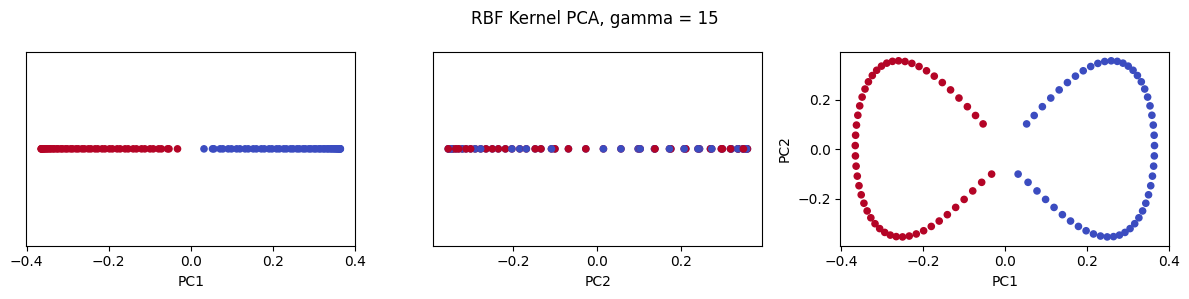

In [ ]:
K_rbf_c = K_rbf - J @ K_rbf - K_rbf @ J + J @ K_rbf @ J
rbf_values, rbf_vectors = np.linalg.eigh(K_rbf_c)
order = np.argsort(rbf_values)[::-1]
rbf_values = rbf_values[order][:2]
rbf_vectors = rbf_vectors[:, order][:, :2]
rbf_alphas = rbf_vectors / np.sqrt(rbf_values)
Z_rbf = K_rbf_c @ rbf_alphas

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].scatter(Z_rbf[:, 0], np.zeros(len(X)), c=y, cmap='coolwarm', s=20)
axes[0].set(xlabel='PC1', yticks=[])
axes[1].scatter(Z_rbf[:, 1], np.zeros(len(X)), c=y, cmap='coolwarm', s=20)
axes[1].set(xlabel='PC2', yticks=[])
axes[2].scatter(Z_rbf[:, 0], Z_rbf[:, 1], c=y, cmap='coolwarm', s=20)
axes[2].set(xlabel='PC1', ylabel='PC2')
fig.suptitle('RBF Kernel PCA, gamma = 15')
plt.tight_layout()
plt.show()


**Společná diskuse**

1. Která komponenta zde pomáhá oddělit půlměsíce?
  - První hlavní komponenta (PC1) – v prvním grafu je vidět, že hodnoty PC1 obou tříd jsou od sebe zcela oddělené podél vodorovné osy (jedna třída má záporné hodnoty, druhá kladné).
2. Použili jsme při výpočtu souřadnic třídy `y`?
  - Nepoužili. Kernel PCA je čistě nepodmíněná (unsupervised) metoda; pracovali jsme pouze se vstupními body $X$. Proměnná $y$ byla použita výhradně pro obarvení bodů v grafu (c=y).
3. Můžeme z tohoto obrázku slíbit stejný výsledek na nových datech?
  - Nemůžeme. Zaprvé jsme hodnotu parametru $\gamma = 15$ mohli nevědomky přizpůsobit (přeučit) tomuto konkrétnímu vzorku, a zadruhé nová testovací data mohou ležet v oblastech, kde se RBF podobnost chová jinak (projekce nových bodů v Kernel PCA vyžaduje vyhodnocení kernelu vůči všem původním trénovacím bodům).


## 11. Nové body: podobnosti vůči trénovacím bodům
Dosavadní $X$ bereme jako trénovací data. Nové body chceme popsat **ve stejných komponentách**.
Nevytváříme nový vlastní rozklad.

Nejdříve sestavíme $K_*=k(X_{test},X)$ s rozměrem $m\times n$.
**Doplňte:** pomocí `cdist` čtvercové vzdálenosti testovacích bodů od trénovacích
a následně RBF kernel se stejným `gamma`.


In [ ]:
from scipy.spatial.distance import cdist

X_test, y_test = make_moons(n_samples=30, noise=.05, random_state=1)
test_distances = cdist(X_test, X)
K_test = np.exp(-gamma * test_distances)
print('Rozměr test–train matice:', K_test.shape)


Rozměr test–train matice: (30, 100)


**Společná diskuse**

1. Proč má tato matice 30 × 100, a ne 30 × 30?
  - Protože nová data musíme popsat v souřadnicovém systému vytvořeném trénovacími daty – každý z 30 testovacích bodů proto potřebuje spočítat svou podobnost (kernel) vůči všem 100 původním trénovacím bodům, jejichž váhy tvoří hlavní směry.
2. Proč zachováváme původní gamma i původní hlavní směry?
  - Abychom nová data promítli do naprosto stejného příznakového prostoru a do stejné báze; změna $\gamma$ nebo směrů by změnila geometrii prostoru i definici komponent a testovací body by nebylo možné s trénovacími vůbec srovnávat.


### 11b. Nové body: centrování a projekce
Odečteme průměrnou podobnost nového bodu ke všem trénovacím bodům (řádkový průměr $K_*$).
Sloupcové průměry a celkový průměr ale převezmeme z **trénovací** matice $K$:
$$K_{*,c}=K_*-\operatorname{rowmean}(K_*)-\operatorname{colmean}(K)+\operatorname{mean}(K).$$
Potom $Z_*=K_{*,c}\alpha$ s již naučenými `rbf_alphas`.

**Doplňte:** uvedené centrování pomocí připravených průměrů a maticový součin pro projekci.


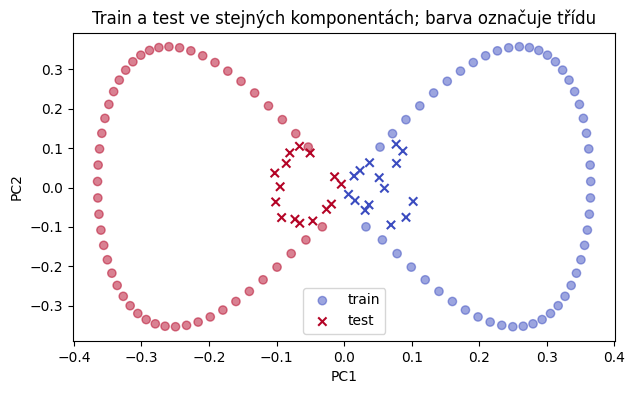

In [ ]:
train_column_mean = K_rbf.mean(axis=0, keepdims=True)
train_total_mean = K_rbf.mean()
test_row_mean = K_test.mean(axis=1, keepdims=True)

K_test_c = K_test - test_row_mean - train_column_mean + train_total_mean
Z_test = K_test_c @ rbf_alphas

plt.figure(figsize=(7, 4))
plt.scatter(Z_rbf[:, 0], Z_rbf[:, 1], c=y, cmap='coolwarm', alpha=.5, label='train')
plt.scatter(Z_test[:, 0], Z_test[:, 1], c=y_test, cmap='coolwarm', marker='x', label='test')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Train a test ve stejných komponentách; barva označuje třídu')
plt.legend()
plt.show()


**Společná diskuse**

1. Které průměry pocházejí z trénovacích dat a který počítáme pro každý nový bod?
  - Z trénovacích dat pocházejí:
    - sloupcové průměry kernelové matice (train_column_mean / $\text{colmean}(K)$),
    - celkový průměr celé trénovací matice (train_total_mean / $\text{mean}(K)$).Pro každý nový bod (jeho řádek v $K_*$) počítáme:
    - řádkový průměr (test_row_mean / $\text{rowmean}(K_*)$), tedy průměrnou podobnost tohoto nového bodu ke všem $N$ trénovacím bodům.
2. Změní se projekce bodu, když jej pošleme samostatně místo ve větší testovací dávce?
  - Nezmění. Každý testovací bod se centruje a promítá zcela nezávisle na ostatních testovacích bodech — v matici $K_*$ počítáme pouze řádkový průměr daného bodu vůči trénovací množině, takže velikost testovací dávky (ať už jde o 1 bod, nebo 1 000 bodů) nemá na výsledné souřadnice žádný vliv.

## 12. Stejný výpočet pomocí scikit-learn
Teď porovnáme vlastní výsledek s hotovou implementací.
`fit_transform` se učí na trénovacích datech; `transform` použije naučený model na nová data.

**Doplňte:** `fit_transform(X)` a `transform(X_test)`.
Nastavení kernelu musí být stejné jako v našem výpočtu.


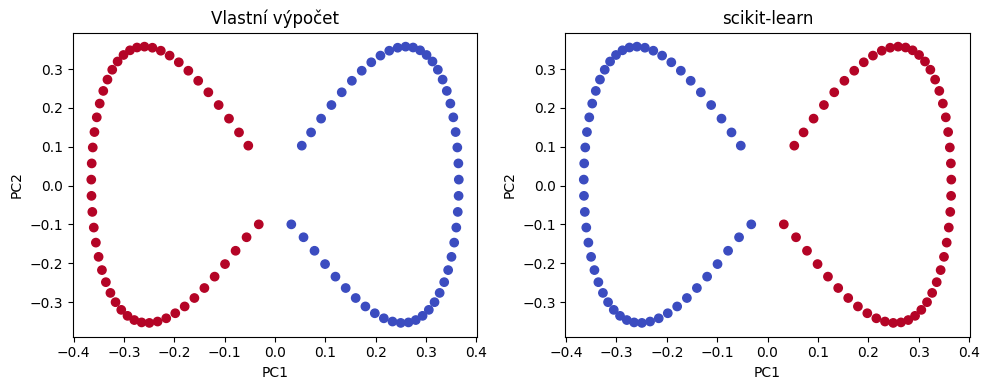

In [ ]:
from sklearn.decomposition import KernelPCA

model = KernelPCA(n_components=2, kernel='rbf', gamma=gamma,
                  eigen_solver='arpack', random_state=0)
Z_sklearn = model.fit_transform(X)
Z_test_sklearn = model.transform(X_test)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(Z_rbf[:, 0], Z_rbf[:, 1], c=y, cmap='coolwarm')
axes[0].set(title='Vlastní výpočet', xlabel='PC1', ylabel='PC2')
axes[1].scatter(Z_sklearn[:, 0], Z_sklearn[:, 1], c=y, cmap='coolwarm')
axes[1].set(title='scikit-learn', xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()


**Společná diskuse**

1. Je případné zrcadlení grafu chybou?
  - Není to chyba. Vlastní vektor $u$ i jeho záporný násobek $-u$ splňují stejnou rovnici $A u = \lambda u$ a oba definují stejný hlavní směr (jen s opačnou orientací osy). Směr znaménka závisí na konkrétním numerickém algoritmu řešiče vlastních čísel.
2. Proč nepoužijeme `fit_transform` také na testovací data?
  - Způsobilo by to únik informací (data leakage) a nekonzistentní reprezentaci. Metoda fit_transform by z testovacích dat spočítala nový vlastní rozklad s novými hlavními směry i novým centrováním, takže výsledné souřadnice testovacích bodů by neodpovídaly souřadnicovému systému trénovacího modelu a nebylo by možné je vzájemně porovnávat.


### 12b. Číselné porovnání
Následující krátká buňka je hotová. Srovná znaménka komponent podle trénovacích dat
a stejnou změnu použije pro test. Vypíše největší absolutní odchylku.


In [ ]:
signs = np.sign((Z_rbf * Z_sklearn).sum(axis=0))
print('Největší odchylka train:', np.max(np.abs(Z_rbf * signs - Z_sklearn)))
print('Největší odchylka test:', np.max(np.abs(Z_test * signs - Z_test_sklearn)))


Největší odchylka train: 3.0531133177191805e-12
Největší odchylka test: 0.28657546993380706


**Společná diskuse**

Proč ani dvě správné numerické implementace nemusí vrátit úplně stejné desetinné číslo?
  1. Různé numerické řešiče a iterační metody:Vlastní rozklad jsme počítali pomocí np.linalg.eigh (který provádí plný exaktní rozklad přes LAPACK/divide-and-conquer), zatímco scikit-learn použil aproximační iterační metodu eigen_solver='arpack' (Arnoldiho/Lanczosův proces). Iterační algoritmy se zastavují při dosažení zadané tolerance (tol), nikoli při absolutní strojové nule.
  2. Zaokrouhlovací chyby při reprezentaci čísel (float64):Při operacích s maticemi dochází k mírně odlišnému pořadí sčítání a násobení v procesoru a BLAS knihovnách. Protože sčítání s plovoucí řádovou čárkou není striktně asociativní, vznikají drobné numerické diference (u trénovacích dat řádově $10^{-12}$).
  3. Propagace a zesílení odchylky při projekci testovacích dat:U testovacích dat se odchylka zvětší (zde na ~0.28), protože malé rozdíly ve váhových vektorech $\alpha$ a drobně odlišné způsoby centrování (např. zda se mezivýpočty provádí jako skaláry, maticově, nebo přes centrovaný operátor) se při maticovém násobení $K_* \alpha$ a normalizaci sčítají a škálují přes celou dimenzi.

## 13. Společný experiment s parametry
Nejdříve odhadněte, co se změní. Potom spusťte vždy jednu variantu a společně ji popište.
Použijeme hotovou implementaci, abychom se soustředili na vliv parametrů.

**Doplňte:** hodnotu `gamma_try`. Postupně vyzkoušejte **0,1; 1; 15; 100;10000**.
Každá varianta používá nový model pouze pro tento experiment.


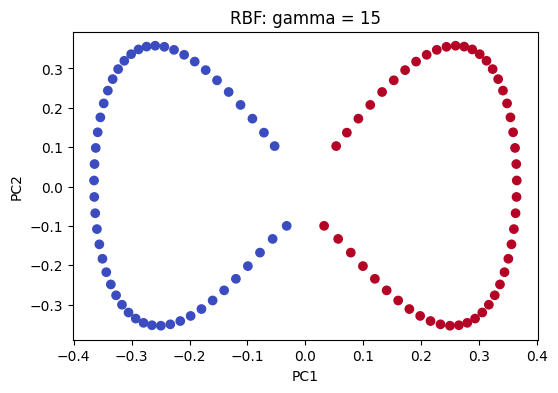

In [ ]:
gamma_try = 15
model_try = KernelPCA(n_components=2, kernel='rbf', gamma=gamma_try,
                      eigen_solver='arpack', random_state=0)
Z_try = model_try.fit_transform(X)

plt.figure(figsize=(6, 4))
plt.scatter(Z_try[:, 0], Z_try[:, 1], c=y, cmap='coolwarm')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'RBF: gamma = {gamma_try}')
plt.show()


**Společná diskuse**

1. Odpovídá obrázek vaší předpovědi?
  - Ano. Při malém $\gamma$ ($0.1, 1$) zůstává zachován zakřivený tvar a třídy se neoddělí, při $\gamma = 15$ dochází k čisté separaci podél PC1, a při extrémních hodnotách ($100, 10\,000$) se globální struktura zhroutí do izolovaných bodů či bezvýznamného mraku.
2. Je větší gamma vždy lepší?
  - Není. Příliš velké $\gamma$ vede k extrémnímu přeučení (overfittingu) – kernel zohledňuje pouze bezprostřední mikrosousedství každého bodu, ztrácí pojem o globálním tvaru dat a pro libovolný nový testovací bod vrátí nulovou podobnost ke všem trénovacím bodům.
3. Pokud vybíráme gamma podle barev tříd, využíváme tím štítky?
  - Ano, v tom případě už postupujeme supervised (s učitelem). Samotný algoritmus Kernel PCA štítky nepotřebuje, ale jakmile člověk nebo optimalizační smyčka ladí hyperparametr $\gamma$ podle toho, jak dobře jsou barevné třídy vizuálně či metricky oddělené, stává se výběr modelu závislým na znalosti cílové proměnné $y$.


### 13b. Stupeň polynomu
**Doplňte:** `degree_try`. Postupně porovnejte **2; 3; 10**.
Parametry `gamma=1` a `coef0=1` zachovávají náš původní vzorec.


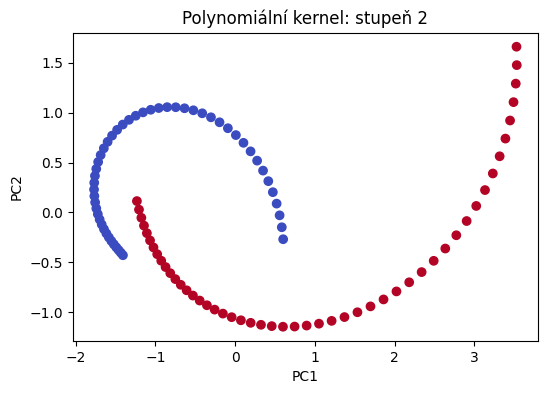

In [ ]:
degree_try = 2
model_poly_try = KernelPCA(n_components=2, kernel='poly', degree=degree_try,
                           gamma=1., coef0=1., eigen_solver='arpack', random_state=0)
Z_poly_try = model_poly_try.fit_transform(X)

plt.figure(figsize=(6, 4))
plt.scatter(Z_poly_try[:, 0], Z_poly_try[:, 1], c=y, cmap='coolwarm')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'Polynomiální kernel: stupeň {degree_try}')
plt.show()


**Společná diskuse**

1. Které body se při zvýšení stupně nejvíc vzdálily od ostatních?
  - Nejvíce se vzdálily krajní body s největší vzdáleností od počátku (body na okrajích půlměsíců s velkou normou $\Vert{}x\Vert{}$).
    - Důvod: Polynomiální kernel počítá $(x^T x' + 1)^d$. Pro body ležící dále od středu je skalární součin větší než 1 a při umocnění na desátou ($d=10$) roste exponenciálně rychleji než pro body blízko počátku.
2. Mění se jen tvar grafu, nebo i rozsah jeho os?
  - Mění se zásadně i rozsah os.
    - Důvod: Se zvyšujícím se stupněm $d$ rostou hodnoty v kernelové matici $K$ o mnoho řádů (u stupně 2 jsou v řádu desítek, u stupně 10 v řádu desítek milionů). Tomu odpovídají podstatně větší vlastní čísla $\lambda$ a následně i výrazně větší rozptyl a rozsah souřadnic v projekci $Z$.


## 14. Soustředné kružnice
Přeneseme stejný postup na jinou geometrii.
Na pomalém počítači lze pro společný pokus snížit počet bodů na 300.


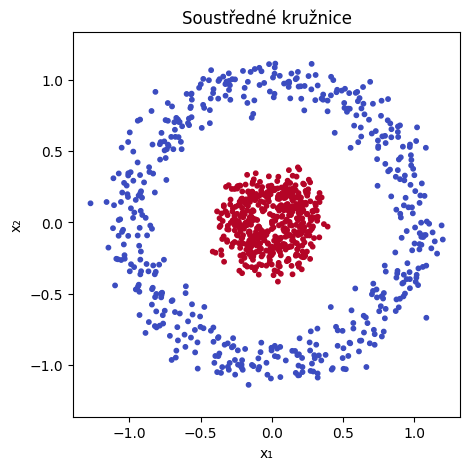

In [ ]:
from sklearn.datasets import make_circles

X_circle, y_circle = make_circles(n_samples=1000, random_state=123, noise=.1, factor=.2)
plt.figure(figsize=(5, 5))
plt.scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, cmap='coolwarm', s=10)
plt.xlabel('x₁')
plt.ylabel('x₂')
plt.title('Soustředné kružnice')
plt.axis('equal')
plt.show()


**Společná diskuse**

1. Jaké jediné číslo by pomohlo rozlišit vnitřní a vnější kružnici?
  - Vzdálenost bodu od počátku (neboli poloměr $r = \sqrt{x_1^2 + x_2^2}$, případně čtverec vzdálenosti $x_1^2 + x_2^2$).Vnitřní kružnice má body s malým poloměrem, zatímco vnější kružnice s velkým poloměrem. Toto jediné číslo (skalár) obě třídy dokonale oddělí.



### 14b. Kružnice: polynomiální Kernel PCA
Nyní už známe všechny kroky. Pro opakování je provedeme přímo, bez pomocné funkce.
Centrování tentokrát zapíšeme pomocí průměrů — je to stejná operace jako s maticí `J`.

**Doplňte:** polynomiální kernel a projekci. Začněte stupněm 2, pak společně zkuste 10.


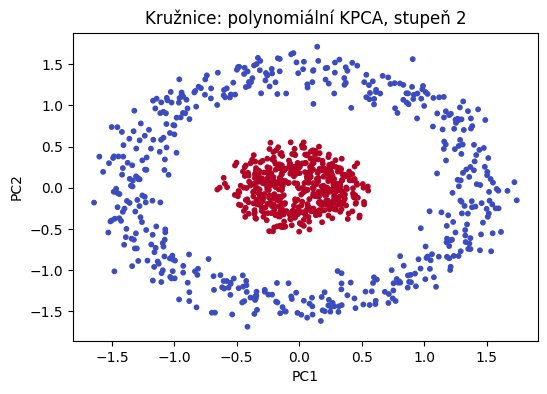

In [ ]:
degree_circle = 2
K_circle_poly = (X_circle @ X_circle.T + 1) ** degree_circle
K_circle_poly_c = (K_circle_poly
                   - K_circle_poly.mean(axis=0, keepdims=True)
                   - K_circle_poly.mean(axis=1, keepdims=True)
                   + K_circle_poly.mean())

circle_poly_values, circle_poly_vectors = np.linalg.eigh(K_circle_poly_c)
order = np.argsort(circle_poly_values)[::-1]
circle_poly_values = circle_poly_values[order][:2]
circle_poly_vectors = circle_poly_vectors[:, order][:, :2]
circle_poly_alphas = circle_poly_vectors / np.sqrt(circle_poly_values)
Z_circle_poly = K_circle_poly_c @ circle_poly_alphas

plt.figure(figsize=(6, 4))
plt.scatter(Z_circle_poly[:, 0], Z_circle_poly[:, 1], c=y_circle, cmap='coolwarm', s=10)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'Kružnice: polynomiální KPCA, stupeň {degree_circle}')
plt.show()


**Společná diskuse**

1. Je oddělení v prvních dvou komponentách takové, jaké jste očekávali?
  - Ano. Už polynom 2. stupně ($d = 2$) obsahuje kvadratické členy $x_1^2$ a $x_2^2$, které přímo odpovídají čtverci vzdálenosti od středu ($r^2$). Díky tomu se původně do sebe vnořené soustředné kružnice v transformovaném prostoru „rozbalí“ a v rovině PC1–PC2 jsou od sebe obě třídy lineárně oddělitelné (jedna třída tvoří shluk oddělený od druhé).
2. Proč ani vhodná nelineární transformace nezaručí, že je informace o třídě v PC1?
  - Protože Kernel PCA je nepodmíněná (unsupervised) metoda, která maximalizuje celkový rozptyl dat v transformovaném prostoru, nikoliv oddělitelnost tříd:
    - Směr PC1 zachycuje osu s největším celkovým rozptylem (který může být způsoben např. nesymetrií, protáhlostí vnější kružnice nebo šumem), zatímco informace rozlišující třídy může mít menší rozptyl a skončit až v PC2 nebo další komponentě.
    - Algoritmus nezná štítky $y$ — pokud bychom chtěli garantovat, že první komponenta maximalizuje separaci tříd, museli bychom použít metodu s učitelem, například Kernel Fisher Discriminant Analysis (KDA/GDA).


### 14c. Kružnice: RBF Kernel PCA
**Doplňte:** RBF kernel a vlastní rozklad centrované matice.
Začněte gamma 5, pak zkuste také původní hodnotu 15.


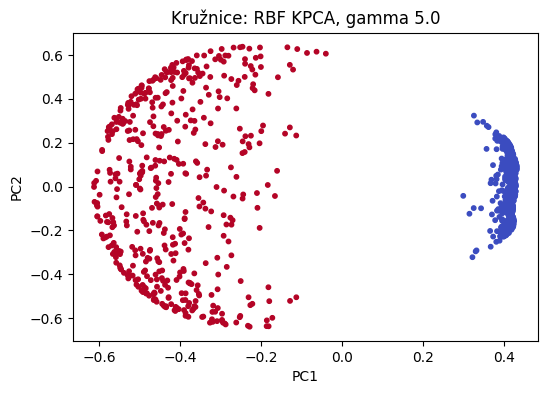

In [ ]:
gamma_circle = 5.
circle_distances = squareform(pdist(X_circle, metric='sqeuclidean'))
K_circle_rbf = np.exp(-gamma_circle * circle_distances)
K_circle_rbf_c = (K_circle_rbf
                  - K_circle_rbf.mean(axis=0, keepdims=True)
                  - K_circle_rbf.mean(axis=1, keepdims=True)
                  + K_circle_rbf.mean())

circle_rbf_values, circle_rbf_vectors = np.linalg.eigh(K_circle_rbf_c)
order = np.argsort(circle_rbf_values)[::-1]
circle_rbf_values = circle_rbf_values[order][:2]
circle_rbf_vectors = circle_rbf_vectors[:, order][:, :2]
circle_rbf_alphas = circle_rbf_vectors / np.sqrt(circle_rbf_values)
Z_circle_rbf = K_circle_rbf_c @ circle_rbf_alphas

plt.figure(figsize=(6, 4))
plt.scatter(Z_circle_rbf[:, 0], Z_circle_rbf[:, 1], c=y_circle, cmap='coolwarm', s=10)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'Kružnice: RBF KPCA, gamma {gamma_circle}')
plt.show()


**Společná diskuse**

1. Jak se liší výsledek od polynomiálního kernelu?
  - Polynomiální kernel (stupeň 2) využívá globální kvadratické vztahy ($x_1^2, x_2^2$), takže body mapuje do parabolického tvaru a obě třídy roztáhne podél hladké křivky.
  - RBF kernel staví na lokální podobnosti bodů (měřítko $\gamma$). Vnitřní kružnice se shlukne do kompaktního celku uprostřed, zatímco vnější kružnice se rozvine do širokého oblouku či prstence kolem něj, přičemž vzdálenost mezi oběma shluky je podstatně ostřeji ohraničená.
2. Co se změní, když zvýšíme šum při generování kružnic?
  - Při větším šumu (noise) se body obou kružnic začnou v původním prostoru prostorově míchat (body vnější kružnice proniknou do poloměru vnitřní a naopak).
  - Tento šum se přenese i do kernelové matice – v projekci dojde k rozptýlení obou shluků a v místech překryvu se body různých tříd začnou prolínat i v PC1 a PC2. RBF kernel navíc při vyšším $\gamma$ začne šum přeučovat (vytváří izolované ostrůvky).
3. Může transformace vždy odstranit překryv tříd?
  - Nemůže. Pokud se dvě třídy překrývají přímo v původním vstupním prostoru (např. dva body s různými třídami leží na stejných souřadnicích $x$ nebo v těsné blízkosti kvůli šumu), žádná deterministická transformace závislá pouze na $X$ je od sebe nedokáže oddělit. Transformace mění pouze zobrazení prostoru, ale nedokáže vytvořit novou informaci, která v datech chybí.


### 14d. Návrat k jednoduché myšlence: poloměr
**Doplňte:** čtverec vzdálenosti od počátku, tedy součet čtverců souřadnic každého bodu.
Porovnáme tento ručně navržený příznak s předchozími reprezentacemi.


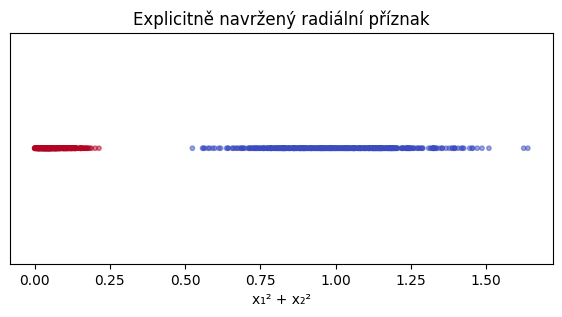

In [ ]:
radius_squared = np.sum(X_circle**2, axis=1)

plt.figure(figsize=(7, 3))
plt.scatter(radius_squared, np.zeros(len(X_circle)), c=y_circle, cmap='coolwarm', s=10, alpha=.5)
plt.xlabel('x₁² + x₂²')
plt.yticks([])
plt.title('Explicitně navržený radiální příznak')
plt.show()


**Společná diskuse**

1. Proč zde stačí jediný příznak?
  - Protože symetrie dat je čistě radiální. Obě třídy se liší pouze svou vzdáleností od počátku souřadnic – vnitřní kružnice má malé hodnoty $r^2 = x_1^2 + x_2^2$ a vnější kružnice velké hodnoty. Tento jediný skalár mapuje celou 2D kružnici do 1D intervalu, kde jsou obě třídy od sebe oddělené jednoduchým prahem (jediným dělícím bodem na ose).
2. Znamená podobné oddělení, že Kernel PCA vypočítala přesně tento příznak?
  - Neznamená.
    - Kernel PCA nehledá explicitní analytický vzorec pro poloměr; vytváří lineární kombinaci bázových funkcí (jader) centrovaných v trénovacích bodech ($\sum_{i=1}^n \alpha_i k(x_i, x)$).
    - V transformovaném prostoru sice první komponenta (nebo jejich kombinace) silně koreluje s poloměrem, ale výsledné souřadnice zahrnují i vyšší harmonické složky, normalizaci, centrování v reprodukujícím Hilbertově prostoru (RKHS) a vliv rozložení bodů.
    - Výsledek tedy plní stejný funkční účel (třídy jsou oddělené), ale matematicky jde o jinou funkci než přesný analytický předpis $x_1^2 + x_2^2$.
